In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pydot
import seaborn as sns

from sklearn.metrics import confusion_matrix, accuracy_score,classification_report

import tensorflow as tf
import keras

from keras.models import Sequential
from keras.layers import Dense, Activation, Dropout
from keras.datasets import fashion_mnist

from keras.utils import to_categorical

from scikeras.wrappers import KerasClassifier

In [2]:
(x_train,y_train),(x_test,y_test)=fashion_mnist.load_data()

In [3]:
y_train

array([9, 0, 0, ..., 3, 0, 5], shape=(60000,), dtype=uint8)

In [4]:
x_train.shape

(60000, 28, 28)

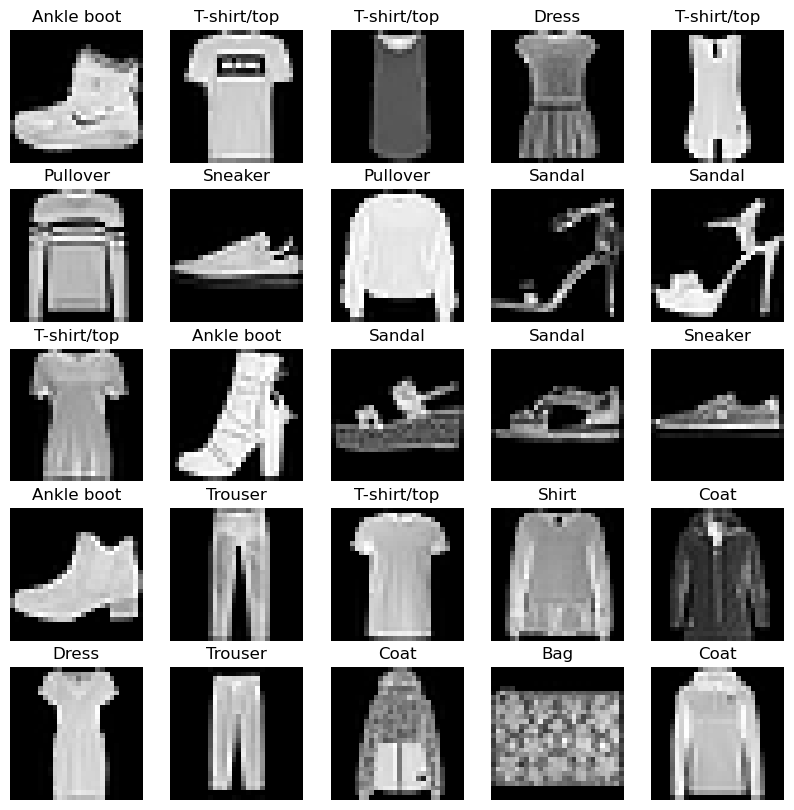

In [5]:
#importing matplotlib for graph
import matplotlib.pyplot as plt
#creating list called column names and storing all the required classes in names
col_names=['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
#creating an empty canvas 10x10 size
plt.figure(figsize=(10,10))
#ireating the first 25 digits of the data  from mnist digit dataset
for i in range(25):
#creating 5x5 matrix
    plt.subplot(5, 5, i+1)
#plt.imshow displays the digits in gray format

    plt.imshow(x_train[i], cmap='gray')
#This will display the corresponding digit number names
    plt.title(col_names[y_train[i]])
    plt.axis('off')

plt.show()

In [6]:
y_train.shape


(60000,)

In [7]:
x_train=x_train.reshape(60000,784)
x_test=x_test.reshape(10000,784)

In [8]:
y_train=to_categorical(y_train,num_classes=10)
y_test=to_categorical(y_test,num_classes=10)

In [9]:
y_train[0]

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 1.])

In [10]:
#Importing all the required libraries for creating ANN
import keras
from keras.models import Sequential
from keras.layers import Dense, Activation, Dropout
from keras import layers
#We are loading empty model here
model = keras.Sequential([
#  Here we specify, no of neurons and input to the input layer.followed by creating  hidden layers and output layer
    layers.Dense(256, activation='relu', input_shape=(784,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='sigmoid')
])

C:\Users\gayut\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │          16,448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 222,218 (868.04 KB)

 Trainable params: 222,218 (868.04 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(loss="categorical_crossentropy",optimizer="adam",metrics=["Accuracy"])

In [13]:
model.fit(x_train,y_train,batch_size=100,epochs=20,validation_data=(x_test,y_test))

Epoch 1/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - Accuracy: 0.6493 - loss: 1.7068 - val_Accuracy: 0.6876 - val_loss: 0.7007
Epoch 2/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - Accuracy: 0.7440 - loss: 0.5603 - val_Accuracy: 0.7772 - val_loss: 0.5711
Epoch 3/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - Accuracy: 0.7656 - loss: 0.4841 - val_Accuracy: 0.7492 - val_loss: 0.5739
Epoch 4/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - Accuracy: 0.7590 - loss: 0.4627 - val_Accuracy: 0.7515 - val_loss: 0.4721
Epoch 5/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - Accuracy: 0.7690 - loss: 0.4278 - val_Accuracy: 0.7802 - val_loss: 0.5069
Epoch 6/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - Accuracy: 0.7724 - loss: 0.4121 - val_Accuracy: 0.7378 - val_loss: 0.4558
Epoch 7/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - Accuracy: 0.7780 - loss: 0.4055 - val_Accuracy: 0.7547 - val_loss: 0.4876
Epoch 8/20
600/600 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - Accuracy: 0.7774 - loss: 0.3842 - val_Accuracy: 0

In [14]:
y_predict=model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [15]:
y_pred=np.argmax(y_predict,axis=1)

In [16]:
y_pred

array([9, 2, 1, ..., 8, 1, 5], shape=(10000,))

In [17]:
y_test_pred=np.argmax(y_test,axis=1)

In [18]:
cm=confusion_matrix(y_test_pred,y_pred)

In [19]:
print(cm)

[[804   1   5  41   3   4 141   0   1   0]
 [  2 970   0  21   1   0   6   0   0   0]
 [ 28   0 786  24  85   1  75   1   0   0]
 [ 22  14   2 907  15   1  36   0   2   1]
 [  0   1  99  79 737   0  83   0   1   0]
 [451   0   0   0   1 514   0  24   0  10]
 [136   0  89  32  53   0 688   0   2   0]
 [  0   0   0   0   0  36   0 952   0  12]
 [  4   0   1  10   1   2  52  10 916   4]
 [  0   0   0   0   0 234   0 302   0 464]]


In [30]:
from tabulate import tabulate

class_names = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

confusion_matrix = pd.DataFrame(cm, index=class_names, columns=class_names)
display(confusion_matrix)


,T-shirt,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
T-shirt,804,1,5,41,3,4,141,0,1,0
Trouser,2,970,0,21,1,0,6,0,0,0
Pullover,28,0,786,24,85,1,75,1,0,0
Dress,22,14,2,907,15,1,36,0,2,1
Coat,0,1,99,79,737,0,83,0,1,0
Sandal,451,0,0,0,1,514,0,24,0,10
Shirt,136,0,89,32,53,0,688,0,2,0
Sneaker,0,0,0,0,0,36,0,952,0,12
Bag,4,0,1,10,1,2,52,10,916,4
Ankle boot,0,0,0,0,0,234,0,302,0,464


In [21]:
classification_report=classification_report(y_test_pred,y_pred)

In [22]:
print(classification_report)

              precision    recall  f1-score   support

           0       0.56      0.80      0.66      1000
           1       0.98      0.97      0.98      1000
           2       0.80      0.79      0.79      1000
           3       0.81      0.91      0.86      1000
           4       0.82      0.74      0.78      1000
           5       0.65      0.51      0.57      1000
           6       0.64      0.69      0.66      1000
           7       0.74      0.95      0.83      1000
           8       0.99      0.92      0.95      1000
           9       0.95      0.46      0.62      1000

    accuracy                           0.77     10000
   macro avg       0.79      0.77      0.77     10000
weighted avg       0.79      0.77      0.77     10000



In [23]:
model.evaluate(x_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - Accuracy: 0.7657 - loss: 0.3917


[0.39168041944503784, 0.7656999826431274]

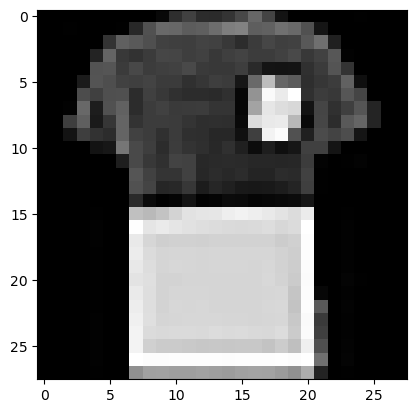

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
Predicted: T-shirt/top
Actual: T-shirt/top


In [24]:
# Fashion-MNIST class labels
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress",
    "Coat", "Sandal", "Shirt", "Sneaker", "Bag",
    "Ankle boot"
]

# 1. Select an image
img = x_test[120]

# 2. Display the image
plt.imshow(img.reshape(28, 28), cmap="gray")
plt.show()

# 3. Predict using ANN
pred = model.predict(img.reshape(1, 784))

# 4. Display predicted clothing name
print("Predicted:", class_names[np.argmax(pred)])

# 5. Display actual clothing name
print("Actual:", class_names[np.argmax(y_test[120])])